<a href="https://colab.research.google.com/github/bushracpu123/assignment3/blob/main/Member4_Generation_Experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Urdu MiniGPT — Member 4: Generation, Evaluation, Experiments & Integration
**Course:** Generative AI & LLM (Fall 2026) · **Assignment 3** · **Tokenizer:** SentencePiece BPE (vocab 2,000)

This notebook is the *runner and presentation layer* for my part of the project. All real logic lives in the
repository's `.py` files (the assignment does **not** accept `.ipynb` as source code):

| Rubric item | Marks | Code (in `src/`) | Where in this notebook |
|---|---|---|---|
| 5.1 Three decoding methods | 6 | `generate.py` | Section 2 |
| 5.2 Urdu continuations + discussion | 4 | `generate.py` (`run_demo`) | Section 3 |
| 6.1 Context length 128 vs 64 | 3 | `experiments.py` | Section 5 |
| 6.2 Attention heads 4 vs 2 | 3 | `experiments.py` | Section 5 |
| 6.3 Temperature 0.5 / 1.0 / 1.5 | 4 | `experiments.py` | Section 4 |
| 7.1 Integration | 2 | all modules wired together | Section 1 |
| Final val/test evaluation | – | `eval_model.py` | Section 6 |

**Pipeline reminder:** Urdu text → *(Member 1)* normalise + SentencePiece BPE → token IDs → *(Member 2/3)* embeddings →
causal-attention Transformer blocks → vocabulary logits → *(Member 4)* choose next token → decode back to Urdu.

## How to run this notebook on Google Colab (T4)
1. **Runtime → Change runtime type → T4 GPU** → Save.
2. Put **`Urdu-MiniGPT-member4-ready.zip`** either in Colab's left 📁 *Files* panel **or** anywhere in your Google Drive
   (e.g. `MyDrive/Urdu-MiniGPT/`). The setup cell mounts Drive, finds the zip by itself and unzips it — even if the zip is wrapped
   inside another zip (e.g. the `files.zip` your browser downloads).
3. **Runtime → Run all.** Everything is automatic. Expect roughly 10–20 minutes in total, most of it the three small
   training runs in Section 5 (they are skipped on a re-run if their results already exist).
4. At the end, Section 7 zips `results/member4/` (plus experiment checkpoints) so you can download it.

## 1. Setup and integration check

In [1]:
# --- Setup: find the project zip automatically (Drive or Colab upload, even if nested) ---------
import os, sys, glob, zipfile, shutil

CONTENT = "/content"
WORK = f"{CONTENT}/work"
ZIP_PATTERN = "Urdu-MiniGPT-member4-ready*.zip"

# 1) Mount Google Drive (a popup asks you to allow access). If you did not upload to Drive, just cancel it.
try:
    from google.colab import drive
    drive.mount(f"{CONTENT}/drive")
except Exception as e:
    print("Drive not mounted:", e)

# 2) Look for the zip in Colab's Files panel and anywhere in My Drive
candidates = glob.glob(f"{CONTENT}/{ZIP_PATTERN}")
candidates += glob.glob(f"{CONTENT}/drive/MyDrive/**/{ZIP_PATTERN}", recursive=True)
candidates += glob.glob(f"{CONTENT}/drive/MyDrive/**/files*.zip", recursive=True)   # browser-downloaded bundle
print("Zip files found:", candidates)

def project_root(base):
    # The project root is the folder that contains src/gpt.py and the tokenizer.
    for dirpath, dirnames, filenames in os.walk(base):
        if os.path.exists(os.path.join(dirpath, "src", "gpt.py")) and os.path.isdir(os.path.join(dirpath, "tokenizer")):
            return dirpath
    return None

def unzip_all(zip_path, dest, depth=0):
    # Extract a zip; if it contains more zips (wrapper zip), extract those too.
    os.makedirs(dest, exist_ok=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dest)
    if depth < 3:
        for inner in glob.glob(f"{dest}/**/*.zip", recursive=True):
            unzip_all(inner, inner[:-4] + "_unzipped", depth + 1)

PROJECT_DIR = project_root(WORK) if os.path.isdir(WORK) else None
if PROJECT_DIR is None:
    assert candidates, ("No project zip found. Upload Urdu-MiniGPT-member4-ready.zip to Colab (Files panel) "
                        "or to your Google Drive, then run this cell again.")
    shutil.rmtree(WORK, ignore_errors=True)
    for zp in candidates:
        unzip_all(zp, WORK)
        PROJECT_DIR = project_root(WORK)
        if PROJECT_DIR:
            break
assert PROJECT_DIR, "Could not find src/gpt.py inside the zip - is this the full project zip (about 15 MB)?"

# 3) If the three Member-4 scripts only exist as loose files (wrapper zip), copy them into src/
for fname in ("generate.py", "eval_model.py", "experiments.py"):
    target = os.path.join(PROJECT_DIR, "src", fname)
    if not os.path.exists(target):
        loose = glob.glob(f"{WORK}/**/{fname}", recursive=True)
        assert loose, f"{fname} not found anywhere in the zip."
        shutil.copy(loose[0], target)

os.chdir(PROJECT_DIR)                                   # all repo paths are relative to the project root
sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))    # so we can import gpt, tokenizer, generate, ...
print("Project root:", os.getcwd())
print("Contents    :", sorted(os.listdir(".")))

Mounted at /content/drive
Zip files found: ['/content/drive/MyDrive/Urdu-MiniGPT/Urdu-MiniGPT-member4-ready.zip']
Project root: /content/work/Urdu-MiniGPT-member4-ready_unzipped/Urdu-MiniGPT
Contents    : ['.gitignore', 'README_member4_section.md', 'attention_results', 'checkpoints', 'notebooks', 'processed_data', 'requirements.txt', 'results', 'src', 'test_attention.py', 'tokenizer']


In [2]:
# SentencePiece is not pre-installed on Colab; PyTorch, NumPy, Matplotlib and Pandas are.
!pip -q install "sentencepiece>=0.2.0"

import torch
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only (training will be slow!)")

PyTorch: 2.14.1+cu130
GPU available: True | Tesla T4


In [3]:
# Integration check: every file the pipeline needs must be present.
required = [
    "tokenizer/urdu_bpe.model", "tokenizer/urdu_bpe.vocab",            # Member 1
    "processed_data/preprocessed/train.txt",
    "processed_data/preprocessed/val.txt",
    "processed_data/preprocessed/test.txt",
    "src/attention.py", "src/gpt.py", "src/config.py",                 # Members 2 & 3
    "src/batch.py", "src/checkpoint.py", "src/train.py",
    "checkpoints/best_model.pt",                                       # Member 3's trained model
    "src/generate.py", "src/eval_model.py", "src/experiments.py",      # Member 4 (me)
]
missing = [p for p in required if not os.path.exists(p)]
print("All required files found." if not missing else f"MISSING: {missing}")
assert not missing

All required files found.


### 1.1 Load the tokenizer and the trained model
We reuse Member 1's tokenizer and Member 3's best checkpoint (`checkpoints/best_model.pt`).
`load_model()` rebuilds `GPTModel` with the configuration from `config.py`
(context 128, D = 128, 4 heads, 4 blocks, dropout 0.1), loads the weights and switches to **eval mode**
(dropout off), which is required for deterministic evaluation and generation.

In [4]:
import math, json, random
import numpy as np
import pandas as pd
import torch.nn.functional as F
from IPython.display import display, HTML, Image

from tokenizer import UrduBPETokenizer
from preprocessing import normalize_urdu_text
from generate import (load_model, generate_ids, generate_text, greedy_next_token,
                      temperature_next_token, top_k_next_token, repetition_stats,
                      continuation_nll, run_sanity_checks, run_demo, default_banned_ids,
                      REQUIRED_PROMPT, DEMO_PROMPTS, DEMO_SETTINGS, DEFAULT_CHECKPOINT)
from eval_model import load_split_tokens, evaluate_split

device = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

tok = UrduBPETokenizer()
model, model_cfg, ckpt = load_model(DEFAULT_CHECKPOINT, device)
BLOCK = model_cfg["block_size"]

print("Tokenizer vocabulary size :", tok.vocab_size)
print("Special ids (unk/bos/eos/pad):", tok.unk_id, tok.bos_id, tok.eos_id, tok.pad_id)
print("Model configuration       :", model_cfg)
print("Trainable parameters      :", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
print("Checkpoint saved at iter  :", ckpt["iteration"], "| saved val loss:", round(ckpt["val_loss"], 4))

Tokenizer vocabulary size : 2000
Special ids (unk/bos/eos/pad): 0 1 2 -1
Model configuration       : {'vocab_size': 2000, 'block_size': 128, 'n_embd': 128, 'n_head': 4, 'n_layer': 4, 'dropout': 0.1}
Trainable parameters      : 1,323,728
Checkpoint saved at iter  : 2800 | saved val loss: 5.0013


In [5]:
# Helper: show Urdu text correctly (right-to-left) inside notebook output tables.
import html as _html
def show_urdu_table(rows, columns):
    """rows: list of dicts; columns: list of (header, key). Urdu cells are rendered RTL."""
    head = "".join(f"<th style='text-align:left'>{h}</th>" for h, _ in columns)
    body = ""
    for r in rows:
        cells_html = ""
        for _, k in columns:
            v = r[k]
            is_text = isinstance(v, str) and any("\u0600" <= ch <= "\u06ff" for ch in v)
            if is_text:
                cells_html += f"<td dir='rtl' style='font-size:18px;text-align:right'>{_html.escape(v)}</td>"
            else:
                cells_html += f"<td>{_html.escape(str(v) if not isinstance(v, float) else format(v, '.3f'))}</td>"
        body += f"<tr>{cells_html}</tr>"
    display(HTML(f"<table><tr>{head}</tr>{body}</table>"))

# Quick tokenizer round trip on the required prompt (normalise -> encode -> decode)
norm = normalize_urdu_text(REQUIRED_PROMPT)
ids = tok.encode(norm)
print("Prompt     :", REQUIRED_PROMPT)
print("Normalised :", norm)
print("Pieces     :", tok.encode_pieces(norm))
print("IDs        :", ids)
print("Decoded    :", tok.decode(ids))

Prompt     : پاکستان میں
Normalised : پاکستان میں
Pieces     : ['پاکستان', '▁میں']
IDs        : [1322, 19]
Decoded    : پاکستان میں


**Note on the required prompt.** In the assignment PDF the Urdu prompt appears reversed/garbled after text extraction
(`ںیم` instead of `میں`). The intended prompt is **«پاکستان میں»** ("In Pakistan"), which is what `REQUIRED_PROMPT` contains.

## 2. Section 5.1 — Three decoding methods
Generation repeats these five steps (implemented in `generate_ids()`):

1. **Crop** the sequence to the last `block_size` (=128) tokens — the position-embedding table only has 128 rows.
2. **Forward pass** → logits of shape `[1, T, V]`.
3. **Take the logits of the last position** → `[1, V]` (the model's prediction for the *next* token).
4. **Choose** the next token with one of the three rules below.
5. **Append** it and repeat.

| Method | Rule | Behaviour |
|---|---|---|
| **Greedy** | `argmax(logits)` | deterministic; most probable token every time → can loop |
| **Temperature sampling** | sample from `softmax(logits / T)` | `T<1` sharper/safer, `T=1` model's own distribution, `T>1` flatter/more random |
| **Top-k sampling** | keep the `k` largest logits, set the rest to `-inf`, then sample (with temperature) | removes the unlikely tail that causes gibberish, still random |

Special tokens `<unk>`, `<s>`, `</s>` are masked out during generation: the model never saw `<s>`/`</s>` in training
(the corpus was encoded as one plain stream) and they decode to empty text.

In [6]:
# Read the three decision rules directly from the source (so you can explain them in the viva).
import inspect
for fn in (greedy_next_token, temperature_next_token, top_k_next_token):
    print(inspect.getsource(fn)); print("-" * 70)

def greedy_next_token(logits):
    """Greedy: always pick the single most likely token (deterministic)."""
    return torch.argmax(logits, dim=-1, keepdim=True)

----------------------------------------------------------------------
def temperature_next_token(logits, temperature=1.0):
    """
    Temperature sampling: divide logits by T, softmax, sample.
      T < 1  -> sharper distribution (safer, more repetitive)
      T = 1  -> the model's own distribution
      T > 1  -> flatter distribution (more random, less coherent)
    """
    if temperature <= 0:
        raise ValueError("temperature must be > 0 (use greedy for T -> 0)")
    probs = F.softmax(logits / temperature, dim=-1)
    return torch.multinomial(probs, num_samples=1)

----------------------------------------------------------------------
def top_k_next_token(logits, k=40, temperature=1.0):
    """
    Top-k sampling: keep only the k highest logits, set the rest to -inf,
    then do temperature sampling among those k cand

### 2.1 Trace one generation step (good viva material)
We feed the prompt once, look at the distribution over the next token, and show what each rule would pick.

In [7]:
x = torch.tensor([tok.encode(normalize_urdu_text(REQUIRED_PROMPT))], device=device)
with torch.no_grad():
    logits = model(x)                          # [1, T, V]
print("input ids shape :", tuple(x.shape), "-> logits shape:", tuple(logits.shape))
last = logits[:, -1, :].clone()                # logits of the LAST position only: [1, V]
last[:, list(default_banned_ids(tok))] = float("-inf")   # same masking as generation

probs = F.softmax(last, dim=-1)[0]
top = torch.topk(probs, 10)
rows = [{"rank": r + 1, "piece": tok.get_piece(int(i)), "id": int(i), "probability": float(p)}
        for r, (p, i) in enumerate(zip(top.values, top.indices))]
display(pd.DataFrame(rows))

torch.manual_seed(0)
print("Greedy picks               :", tok.get_piece(int(greedy_next_token(last))))
print("Temperature (T=0.8) samples:", [tok.get_piece(int(temperature_next_token(last, 0.8))) for _ in range(5)])
print("Top-k (k=5, T=0.8) samples :", [tok.get_piece(int(top_k_next_token(last, 5, 0.8))) for _ in range(5)])

input ids shape : (1, 2) -> logits shape: (1, 2, 2000)


,rank,piece,id,probability
0,1,▁سے,32,0.029368
1,2,▁بھی,80,0.019722
2,3,▁ایک,70,0.019439
3,4,▁ان,47,0.016270
4,5,▁اس,37,0.016127
5,6,▁یہ,81,0.016092
6,7,▁کیا,87,0.014218
7,8,▁شامل,381,0.014051
8,9,▁م,5,0.011996
9,10,▁پ,10,0.011231


Greedy picks               : ▁سے
Temperature (T=0.8) samples: ['▁کسی', '▁سب', '▁وزیراعظم', '▁کامیاب', '▁۱۸']
Top-k (k=5, T=0.8) samples : ['▁بھی', '▁ایک', '▁ایک', '▁اس', '▁بھی']


### 2.2 Sanity checks — do the decoders really do what they claim?

In [8]:
checks = run_sanity_checks(model, tok, BLOCK, device)
display(pd.DataFrame({"check": list(checks), "passed": list(checks.values())}))
assert all(checks.values()), "A decoding check failed!"

,check,passed
0,greedy_is_argmax,True
1,top_k_stays_inside_top_k,True
2,top_k_uses_several_tokens,True
3,low_temperature_is_almost_greedy,True
4,entropy_grows_with_temperature,True
5,special_tokens_never_generated,True
6,long_prompt_is_cropped_not_crashing,True
7,greedy_is_reproducible,True
8,sampling_is_reproducible_with_seed,True


## 3. Section 5.2 — Urdu continuations
Five prompts (the required one + four more) × three decoding settings, 40 new tokens each, fixed seed 42.
For each output we also compute *numbers* that make the discussion concrete:

* **distinct-1** — unique tokens / all tokens (1.0 = no repeated token)
* **repeated 3-gram** — share of 3-token windows that already occurred (high = looping)
* **longest run** — longest streak of the same token back-to-back
* **NLL** — average negative log-likelihood the model assigns to its own text at T = 1 (low = "safe", high = "surprising")

In [9]:
samples = run_demo(model, tok, BLOCK, device, DEMO_PROMPTS, max_new_tokens=40, seed=SEED)
show_urdu_table(samples, [("Prompt", "prompt"), ("Setting", "setting"), ("Generated text", "full_text"),
                          ("distinct-1", "distinct_1"), ("rep. 3-gram", "repeated_trigram"),
                          ("longest run", "longest_run"), ("NLL", "continuation_nll")])
print("Saved: results/member4/generation_samples.json and .md")

Prompt,Setting,Generated text,distinct-1,rep. 3-gram,longest run,NLL
پاکستان میں,greedy,پاکستان میں سے پہلے ہی اس کے ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ (ص) زیادہ کے ساتھ (۱) زیادہ,0.275,0.579,25,2.050
پاکستان میں,temperature (T=0.8),پاکستان میں ہر شخص کی قیمتوں میں اس کے لائیںتے ہیں کہ وہ کام نہیں چاہے سے احسپی ختم ہو سکتا کیوں کھاتے ہیں کہ ہر اور اس کے علاوہ کسی کو ۱۰ سال کو,0.850,0.000,1,3.583
پاکستان میں,"top-k (k=40, T=0.8)",پاکستان میں کھول کی قیمتوں میں پاکستان کے لائیں گے ایک نئی ٹیم نے مراپیسکٹر پر سمتھونیورسٹی کا کہنا ہے توڑھارٹی کوئٹے میچ میں,0.950,0.000,1,3.343
وزیر اعظم نے,greedy,وزیر اعظم نے کہا کہ وہ اس کے لیے اس کے بعد اس کے لیے اس کے ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ہی نہیں کر دیا گیا تھا کہ وہ اس کے ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ,0.350,0.474,10,2.530
وزیر اعظم نے,temperature (T=0.8),وزیر اعظم نے اپناالیگرز کی درخواست رکھا تھیہ بھی بنا لیا جبکہ وہ تم مانکوائریکٹر پر سمتھونیسم کپ کا کہنا ہے توڑ، اورفارمندے، ہ,0.975,0.000,1,4.210
وزیر اعظم نے,"top-k (k=40, T=0.8)",وزیر اعظم نے اپنا رضد کی ایک نیا اور ونانچہ کے لیے مراظ سے سادرام مفت کی جاویدعمرے، اور محکلیے نے ہ,0.875,0.000,1,3.767
کرکٹ ٹیم کے,greedy,کرکٹ ٹیم کے مطابق پاکستان میں بھی پاکستان میں پاکستان میں کھیلے گئے ہیں اور پاکستان میں بھی پاکستان میں پاکستان میں پاکستان میں پاکستان میں پاکستان میں پاکستان میں پاکستان میں پاکستان میں پاکستان میں پاکستان میں پاکستان میں کہا گیا,0.275,0.605,1,2.611
کرکٹ ٹیم کے,temperature (T=0.8),کرکٹ ٹیم کے اوپن آفز کی درخواست رکھا تھیہ بھی بنا رہا جبکہ ٹیم نے چیف مدتی سے زائد خواتین میں ختم کر دیا گی اورء نے کہا کہ کورونا وائرس کے دوران کہا۔ “ب کئے,0.950,0.000,1,4.190
کرکٹ ٹیم کے,"top-k (k=40, T=0.8)",کرکٹ ٹیم کے اوپن آفز کی درخواست کی جانب سے بھی شامل کیے جبکہ ٹیم نے مراپ سے زائد سفارش جاری کئے تھی گی اور شادے بلے گی اور تین ایگے میچ میں,0.875,0.000,1,3.714
لاہور میں,greedy,لاہور میں سے زائد یہ ہے کہ وہ اس کے لیے ایک بار پھر آپ کو آپ کو آپ کو آپ کو آپ کو آپ کو آپ کو آپ کو آپ کو آپ کو آپ کو آپنے کے پاس آپ کو,0.400,0.500,1,2.265


Saved: results/member4/generation_samples.json and .md


In [10]:
# Average the repetition statistics per decoding method
df = pd.DataFrame(samples)
display(df.groupby("setting")[["distinct_1", "repeated_trigram", "longest_run", "continuation_nll"]].mean().round(3))

,distinct_1,repeated_trigram,longest_run,continuation_nll
setting,,,,
greedy,0.28,0.611,7.6,2.292
temperature (T=0.8),0.92,0.000,1.0,4.008
"top-k (k=40, T=0.8)",0.89,0.000,1.0,3.637


### 3.1 Discussion of the generated text  *(edit after reading YOUR outputs above)*
Write 1–2 sentences per point, quoting a concrete example and a number from the table. Questions to answer:

* **Fluency** — Are the words real Urdu words? Is the grammar/word order plausible for 2–3 words at a time?
  (The model has only ~1.3 M parameters and saw ~270 K tokens, so expect locally plausible but globally weak text.)
* **Repetition** — Does *greedy* repeat tokens or phrases? Compare its *repeated 3-gram* and *distinct-1* with the sampling methods.
* **Coherence** — Does the continuation stay on the topic of the prompt (news-style text) for the full 40 tokens, or drift?
* **Top-k vs plain temperature** — Does top-k look cleaner than temperature-only at the same T? (Top-k cuts off the unlikely tail.)
* **Failure cases** — see the probes below (loops, drift, broken subwords, unknown characters).

In [11]:
# Failure-case probes -------------------------------------------------------
# (1) Greedy decoding with a long continuation: does it fall into a loop?
long_greedy = generate_text(model, tok, REQUIRED_PROMPT, BLOCK, max_new_tokens=100, method="greedy", device=device)
print("Greedy, 100 new tokens:"); show_urdu_table([long_greedy], [("text", "full_text")])
print(repetition_stats(long_greedy["new_ids"]))

# (2) Very high temperature: is the text still Urdu-like?
hot = generate_text(model, tok, REQUIRED_PROMPT, BLOCK, max_new_tokens=40, method="temperature", temperature=2.0, seed=1, device=device)
print("\nTemperature 2.0:"); show_urdu_table([hot], [("text", "full_text")])

# (3) Out-of-vocabulary character in the prompt (emoji): handled by <unk>, then the model continues
oov = generate_text(model, tok, "پاکستان 🧬", BLOCK, max_new_tokens=20, method="top_k", device=device)
print("\nPrompt with unseen character -> prompt ids:", oov["prompt_ids"], "(0 = <unk>)")
show_urdu_table([oov], [("text", "full_text")])

Greedy, 100 new tokens:


text
پاکستان میں سے پہلے ہی اس کے ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ (ص) زیادہ کے ساتھ (۱) زیادہ کے ساتھ (۱) زیادہ کے ساتھ (۳) زیادہ کے ساتھ (۳) زیادہ) زیادہ کے ساتھ (۱) زیادہ کے ساتھ (۱) زیادہ کے ساتھ (۱۴) زیادہ کے ساتھ (۱) زیادہ کے ساتھ (۳) زیادہ کے ساتھ (۱) زیادہ کے ساتھ (


{'n_tokens': 100, 'distinct_1': 0.13, 'repeated_trigram': 0.7551020408163265, 'longest_run': 25}

Temperature 2.0:


text
پاکستان میں اضشد کے مارچ ٹین پاکستان اہل شنہسم قتل سے زائد اححشایت سوچ جائے چونکہ۳ سندھ آپ ظ پاد عالیر دینافاشن کے مشتمل اور ترب فھا ہوتے



Prompt with unseen character -> prompt ids: [1322, 1837, 0] (0 = <unk>)


text
پاکستان ⁇ اور ہجز کی ایک نفس اور خال کی طرف سے گورنداد سے س


## 4. Experiment 6.3 — Temperature (0.5, 1.0, 1.5)
Same checkpoint, same prompts, **pure temperature sampling** (no top-k), 10 seeds per (prompt, T) so the averages are not luck.
We compare randomness and repetition numerically and keep one representative text per setting.

,mean_distinct_1,mean_repeated_trigram,mean_longest_run,mean_continuation_nll
temperature,,,,
0.5,0.808,0.011,1.300,2.973
1.0,0.933,0.000,1.133,4.657
1.5,0.963,0.000,1.133,6.553


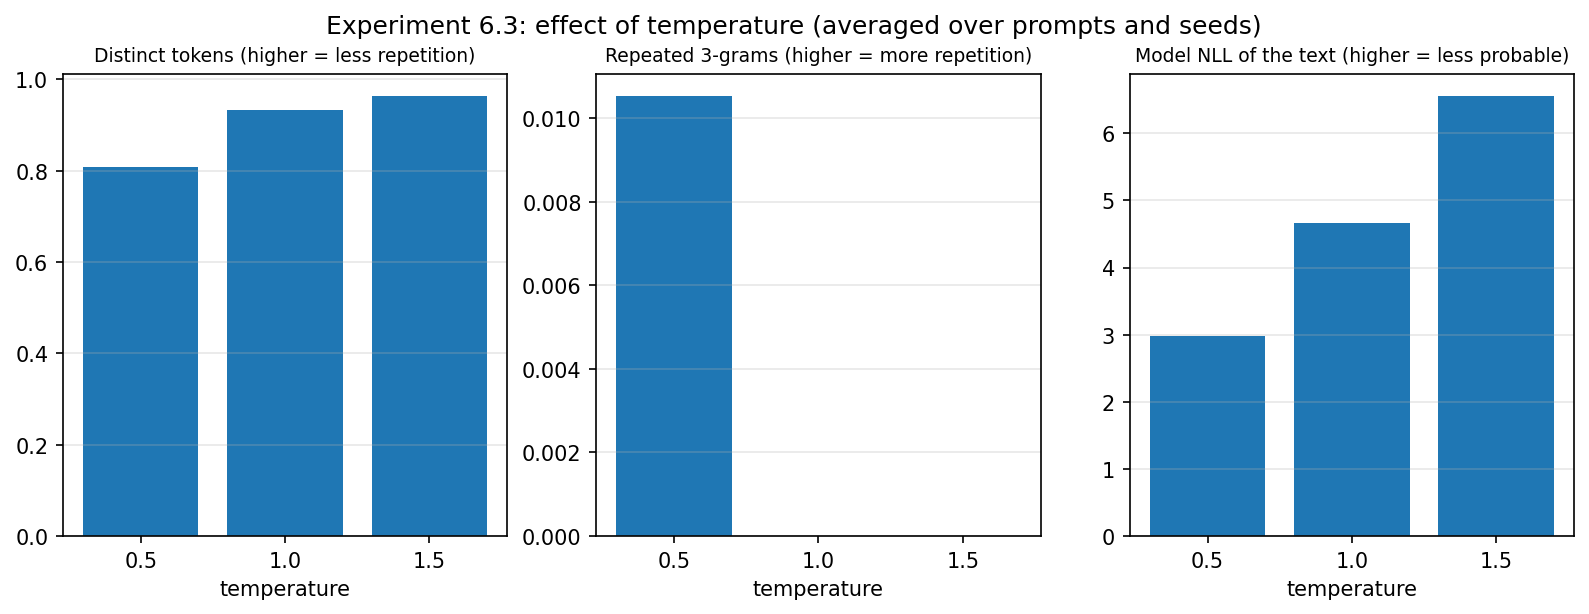

In [12]:
from experiments import run_temperature_experiment
temp_rows = run_temperature_experiment(device, n_samples=10, max_new_tokens=40)

summary = pd.DataFrame(temp_rows).groupby("temperature")[
    ["mean_distinct_1", "mean_repeated_trigram", "mean_longest_run", "mean_continuation_nll"]].mean().round(3)
display(summary)
display(Image("results/member4/temperature_experiment.png"))

In [13]:
# Representative generations for the required prompt
show_urdu_table([r for r in temp_rows if r["prompt"] == REQUIRED_PROMPT],
                [("T", "temperature"), ("Example output", "example_text"),
                 ("distinct-1", "mean_distinct_1"), ("rep. 3-gram", "mean_repeated_trigram")])

T,Example output,distinct-1,rep. 3-gram
0.500,پاکستان میں مانگا کو اس موقع پرویز مشرف سے زیادہ سے زیادہ سے باہر کر سکیں گے جو ابتدتی ہے اور ان کے بعد یہاں تک کہ یہ ایک ہی گٹیں کسی,0.795,0.013
1.000,پاکستان میں کبھی بھی اسے جذب کرنے والی ورزی ہے اور ہماری ٹیم سے کیفیکولیاتی عہدوں سے معلومات جنرل مشتر نہیں ہوتی ہیں۔ جاں چلانا گے۔ ڈاکٹر کی حکومت کو اپیلیں,0.922,0.000
1.500,پاکستان میں کبھی بھی آساناٹ کیا۔ او پلان چاہی امتنجون سےلزفیہ اختت ٹریئیے سے معلومات ال مشتام نہیں بھ جع چلانا گے۔ قرآن دیں ان کو اپیلیں,0.957,0.000


### 4.1 Discussion  *(edit after reading YOUR numbers above)*
Use the summary table and the examples to explain, for each temperature:

* **Randomness:** how different are the 10 samples from each other? (Compare the 10 `all_texts` in `temperature_experiment.json`.)
* **Repetition:** how do *distinct-1* and *repeated 3-gram* change from 0.5 → 1.0 → 1.5?
* **Coherence / probability:** how does the model's own NLL of the text change? Low temperature = text the model finds likely;
  high temperature = text the model itself finds unlikely, which usually reads as incoherent.
* **Why:** dividing logits by `T` rescales them before softmax — `T<1` widens the gap between the top token and the rest,
  `T>1` shrinks it, so unlikely tokens get sampled more often.

## 5. Experiments 6.1 and 6.2 — Context length and attention heads
| Run | Context | Heads | Head dim | Purpose |
|---|---|---|---|---|
| `ctx128_h4` | 128 | 4 | 32 | baseline (= Member 3's configuration) |
| `ctx64_h4`  | **64** | 4 | 32 | **6.1** — only the context length changes |
| `ctx128_h2` | 128 | **2** | **64** | **6.2** — only the head count changes; embedding dim stays 128 |

All three runs use the same code, seed (42), optimiser (AdamW, lr 3e-4), batch size 16, 3,000 iterations and dropout 0.1.
The best-validation checkpoint of each run is saved as `checkpoints/exp_<name>.pt` (Member 3's checkpoint is untouched),
then evaluated on the **whole** validation split. Note that the 2-head model has the *same number of parameters* as the 4-head model
(heads only split the same `128 → 128` projections), so any difference comes from how attention is organised, not from model size.

In [14]:
RUN_TRAINING = True      # set False to only load previously saved results
SUMMARY_PATH = "results/member4/experiments_summary.json"

from experiments import run_training_experiments
if os.path.exists(SUMMARY_PATH) and not globals().get("FORCE_RETRAIN", False):
    print("Found saved results - loading them (set FORCE_RETRAIN = True to retrain).")
    exp_results = json.load(open(SUMMARY_PATH, encoding="utf-8"))
elif RUN_TRAINING:
    exp_results = run_training_experiments(device, max_iters=3000)     # ~ a few minutes per run on a T4
else:
    raise SystemExit("No saved results and RUN_TRAINING=False")


=== ctx128_h4: context=128, heads=4, head_dim=32, params=1,323,728 ===
  iter  100/3000 | train 6.6015 | val 6.5908
  iter  200/3000 | train 6.5269 | val 6.4984
  iter  300/3000 | train 6.3386 | val 6.3514
  iter  400/3000 | train 6.1211 | val 6.1481
  iter  500/3000 | train 5.9306 | val 5.9765
  iter  600/3000 | train 5.7724 | val 5.8251
  iter  700/3000 | train 5.5882 | val 5.6805
  iter  800/3000 | train 5.4748 | val 5.6074
  iter  900/3000 | train 5.3981 | val 5.5109
  iter 1000/3000 | train 5.2472 | val 5.3973
  iter 1100/3000 | train 5.1675 | val 5.4092
  iter 1200/3000 | train 5.1123 | val 5.3317
  iter 1300/3000 | train 5.0428 | val 5.2410
  iter 1400/3000 | train 4.9398 | val 5.2092
  iter 1500/3000 | train 4.9105 | val 5.1954
  iter 1600/3000 | train 4.8784 | val 5.1594
  iter 1700/3000 | train 4.8435 | val 5.1140
  iter 1800/3000 | train 4.7614 | val 5.0925
  iter 1900/3000 | train 4.7050 | val 5.1008
  iter 2000/3000 | train 4.7253 | val 5.0591
  iter 2100/3000 | train 4.6

,run,context,heads,head_dim,params,train_sec,best_iter,val_loss,val_perplexity,val_loss@64-token windows
0,ctx128_h4,128,4,32,1323728,48.5,2600,5.0144,150.57,5.0187
1,ctx64_h4,64,4,32,1315536,48.7,2900,5.0284,152.69,5.0284
2,ctx128_h2,128,2,64,1323728,47.8,2600,5.0137,150.47,5.0185
3,member3_checkpoint,128,4,32,1323728,NaN,2800,5.0331,153.40,5.0418


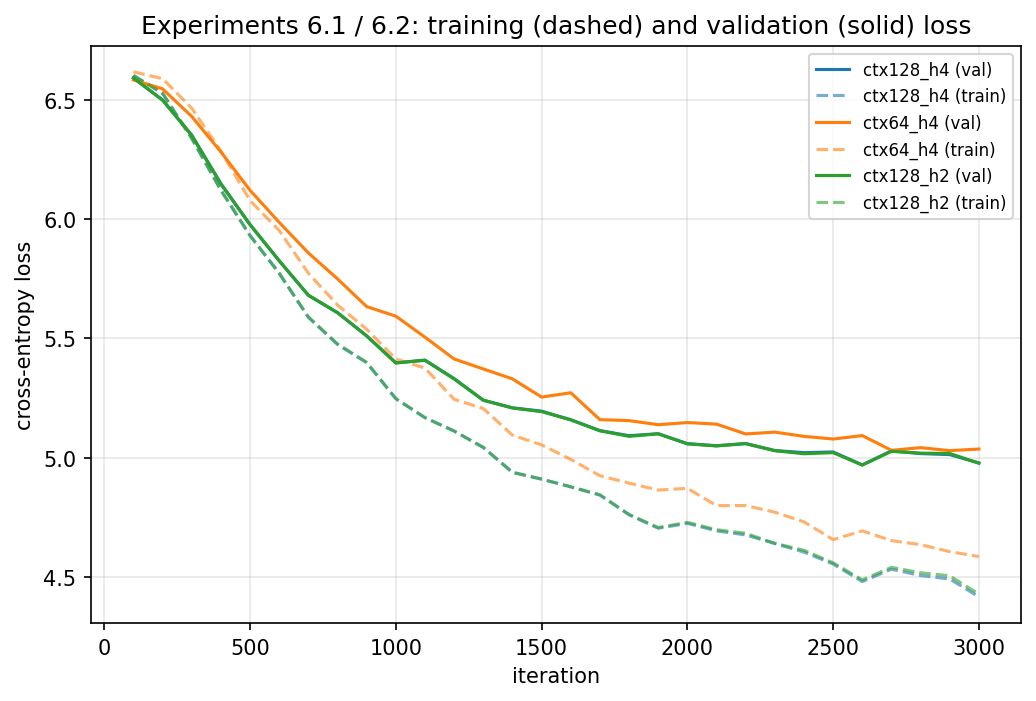

In [15]:
table = pd.DataFrame([{
    "run": r["name"], "context": r["block_size"], "heads": r["n_head"], "head_dim": r["head_dim"],
    "params": r["parameters"], "train_sec": r.get("train_seconds"), "best_iter": r.get("best_iteration"),
    "val_loss": round(r["val_loss"], 4), "val_perplexity": round(r["val_perplexity"], 2),
    "val_loss@64-token windows": round(r["val_loss_64token_windows"], 4),
} for r in exp_results])
display(table)
display(Image("results/member4/experiments_loss_curves.png"))

**How to read the table**

* `val_loss` / `val_perplexity` are measured on the full validation split, with windows of each model's *own* context length.
* `val_loss@64-token windows` scores **every** model on 64-token windows, so the context-64 and context-128 models are compared
  on exactly the same footing (a model with a longer window sees more history for its later tokens, which flatters it in the plain `val_loss`).
* `member3_checkpoint` is Member 3's original run, re-scored with the same evaluator as a consistency check against `ctx128_h4`.

In [16]:
# Representative generations of each variant (same prompts, same seed, same decoding settings)
gen_rows = []
for r in exp_results:
    for g in r.get("generations", []):
        gen_rows.append({"run": r["name"], "prompt": g["prompt"], "setting": g["setting"], "text": g["text"]})
show_urdu_table(gen_rows, [("Run", "run"), ("Prompt", "prompt"), ("Setting", "setting"), ("Generated text", "text")])

Run,Prompt,Setting,Generated text
ctx128_h4,پاکستان میں,greedy,پاکستان میں سے زیادہ سے زیادہ ہے۔ اس کے ساتھ (۳) زیادہ کے ساتھ (۳) زیادہ کے ساتھ (۳) زیادہ کے ساتھ (۳) زیادہ کے ساتھ (۱) زیادہ کے ساتھ (۱
ctx128_h4,پاکستان میں,"top-k (k=40, T=0.8)",پاکستان میں کامیاب ہے۔ اس کی طرح ایک قسم کے لائیں۔ ایک طرف سے کام ، ایک ہی سے ، اور سلمبوط ایکٹ کا مطلب کہہ اور اس کے علاوہ ، بریف نے ہ
ctx128_h4,وزیر اعظم نے,greedy,وزیر اعظم نے کہا کہ وہاں کے لیے اس کے ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ ساتھ (۱) زیادہ کے ساتھ (
ctx128_h4,وزیر اعظم نے,"top-k (k=40, T=0.8)",وزیر اعظم نے اپنا رجب کی ایک نیا اور و سلام اللہ تعلیتدھو سادر کی روشک نے شادے کرنے اور اس کے علاوہ ، بریف نے ہ
ctx64_h4,پاکستان میں,greedy,پاکستان میں اضافہ ہوا۔ اس کے لئے ، اس کے لئے ، اور اس کے لئے ، آپ کو ایک اہم ، آپ کو ایک بار ، آپ کو ایک بار ، آپ کو ایک بار پھر آپ کو بھی ،
ctx64_h4,پاکستان میں,"top-k (k=40, T=0.8)",پاکستان میں کامیاب ہے۔ اس کے اندر ایک بار بار اور جو بھی ایک طرف سے گورنرافہ پر مبنی چاہیے۔ اس کے ذریعہ شادے تو ، بروسیکوں کا مطلب کرنے
ctx64_h4,وزیر اعظم نے,greedy,وزیر اعظم نے کہا کہ وہی کی وجہ سے متعلقہ میں بھی نہیں کیا گیا ہے کہ وہ اس کے ساتھ ہی نہیں ہے کہ وہ اس کے ساتھ ساتھ ساتھ ساتھ ساتھ ہی نہیں ہے کہ وہ اس کے ساتھ
ctx64_h4,وزیر اعظم نے,"top-k (k=40, T=0.8)",وزیر اعظم نے اپنا کم بز کی ایک عرصہ اور جو بھی ایک طرف سے گورنرافہ پر مبنی چاہیے۔ اس کے ذریعہ شادیت کرنے والے بروپے کے لئے کا امکان کرنے
ctx128_h2,پاکستان میں,greedy,پاکستان میں ایک بار جب کہ وہاں کے ساتھ ہی نہیں ہو گا اور اس کے ساتھ ہی نہیں ہو سکتا ہے کہ وہاں ادارے سے زیادہ سے زیادہ سے زیادہ سے زیادہ سے زیادہ سے زیادہ سے زیادہ سے
ctx128_h2,پاکستان میں,"top-k (k=40, T=0.8)",پاکستان میں کامیاب ہے۔ اس کے اندر ایک بار بار اور انھیں ایک طرف سے ان کا مظاہرہ اخلاق کو ختم کرنے کا سامنا کرنا ہے۔ انہوں نے کوئی عث میں شرکت نہیں۔ یہ خیال کرنے


### 5.1 Discussion of 6.1 and 6.2  *(edit after reading YOUR numbers above)*
**6.1 Context length (128 vs 64).** State the two validation losses/perplexities and which is better. Then explain *why*:
a longer window lets later tokens attend to more history; with only ~270 K training tokens and a 1.3 M-parameter model the gain may be small.
Mention the fair 64-token-window comparison and whether the generated text differs (e.g. topic drift after ~60 tokens
when generating beyond the shorter context).

**6.2 Attention heads (4 vs 2).** State the validation losses and parameter counts (identical). Explain that 4 heads of dimension 32
can learn more *different* attention patterns, while 2 heads of dimension 64 give each head a richer subspace; at this tiny scale the
difference is expected to be small — say whether your numbers show that, and whether the difference is larger than the run-to-run noise
(a single seed cannot prove a difference; mention this limitation honestly).

## 6. Final evaluation
Validation loss/perplexity of the final model (Member 3's best checkpoint) on the whole split, plus **bits per character**, which is
comparable between the BPE and Unigram groups (token-level perplexity is not — see the note in the dataset instructions).

The **test split must only be used once, after the model is final.** The test cell below is switched off by default.

In [17]:
val_tokens, val_chars = load_split_tokens("val", tok)
val_res = evaluate_split(model, val_tokens, BLOCK, device=device, n_chars=val_chars)
print(f"Validation tokens: {len(val_tokens):,} | loss {val_res['loss']:.4f} | "
      f"perplexity {val_res['perplexity']:.2f} | bits/char {val_res['bits_per_char']:.3f}")

# Token counts for the report (dataset instruction 4e)
for split in ("train", "val", "test"):
    t, c = load_split_tokens(split, tok)
    print(f"{split:>5}: {len(t):>8,} tokens | {c:>8,} characters | {len(t)/c:.3f} tokens/char")

Validation tokens: 34,007 | loss 5.0331 | perplexity 153.40 | bits/char 2.481
train:  267,316 tokens |  799,937 characters | 0.334 tokens/char
  val:   34,007 tokens |   99,547 characters | 0.342 tokens/char
 test:   34,807 tokens |  100,871 characters | 0.345 tokens/char


In [18]:
# >>> RUN THIS CELL ONLY ONCE, AFTER THE MODEL IS FINAL <<<
RUN_TEST_EVAL = False
if RUN_TEST_EVAL:
    test_tokens, test_chars = load_split_tokens("test", tok)
    test_res = evaluate_split(model, test_tokens, BLOCK, device=device, n_chars=test_chars)
    print(f"TEST: loss {test_res['loss']:.4f} | perplexity {test_res['perplexity']:.2f} | bits/char {test_res['bits_per_char']:.3f}")
    json.dump(test_res, open("results/member4/eval_test.json", "w"), indent=2)
else:
    print("Test evaluation skipped (set RUN_TEST_EVAL = True when everything else is final).")

Test evaluation skipped (set RUN_TEST_EVAL = True when everything else is final).


## 7. Save everything for the repository and the report
`write_report_tables()` produces Markdown tables you can copy into `Report.pdf`. The last cell zips the outputs for download.

In [ ]:
from experiments import write_report_tables
print(write_report_tables(exp_results, temp_rows))

In [ ]:
import shutil
os.makedirs("download", exist_ok=True)
shutil.make_archive("download/member4_results", "zip", "results/member4")
for f in ("checkpoints/exp_ctx128_h4.pt", "checkpoints/exp_ctx64_h4.pt", "checkpoints/exp_ctx128_h2.pt"):
    if os.path.exists(f): shutil.copy(f, "download/")
print(os.listdir("download"))

try:
    from google.colab import files
    files.download("download/member4_results.zip")        # small: tables, plots, generated text
except Exception as e:
    print("Download manually from the Files panel:", e)

# Optional: also copy to Google Drive so nothing is lost if the runtime disconnects
# from google.colab import drive; drive.mount('/content/drive')
# shutil.copytree("results/member4", "/content/drive/MyDrive/Urdu-MiniGPT-results", dirs_exist_ok=True)

## 8. Contribution row, viva cheat-sheet and Git
**Contribution table row (Member 4):** Text generation (greedy, temperature, top-k; `generate.py`), evaluation on the full val/test
splits (`eval_model.py`), controlled experiments 6.1–6.3 (`experiments.py`), result tables/plots, this runner notebook, and integration
testing of tokenizer → model → checkpoint → generation (end-to-end run on Colab T4).

**Be ready to explain in the viva**
* Why only the **last position's** logits are used, and why the input is cropped to `block_size`.
* Greedy vs temperature vs top-k: formulas, and what happens at `T → 0` and `T → ∞`.
* Why the model must be in `eval()` mode and wrapped in `torch.no_grad()` while generating.
* Why top-k keeps text cleaner but does not fix repetition by itself.
* How the controlled experiments were kept fair (same seed, data, iterations, optimiser; only one factor changed).
* Why 2 heads and 4 heads have the same parameter count.

**Commit your work (from your clone of the repo):**
```bash
git add src/generate.py src/eval_model.py src/experiments.py notebooks/ results/member4/ README.md
git commit -m "Member 4: generation, evaluation and controlled experiments"
git push
```